# Lesson 01 - Explore the data

Good machine learning starts with knowing your data. In this lesson you will:

- see what is recorded for every clip (the **metadata table**),
- count clips and **ships** per class (they are not the same thing!),
- understand the **folds** and why they keep each ship in a single split,
- look at the distance and speed targets,
- listen to a few clips (if the audio zip is on this machine).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import data as D
from labels import CLASSES
from paths import AUDIO_ZIP, DATA_DIR

mel, table = D.open_features(DATA_DIR)
print(f"{len(table)} clips, {table.shape[1]} columns")

43208 clips, 53 columns


## 1. The table: one row per 5-second clip

The most important columns:

| column | meaning |
|---|---|
| `label` | the class: 11 ship types or `background` (no ship within 8 km) |
| `MMSI` | the ship's ID from its AIS radio beacon (0 for background) |
| `hydrophone` | which underwater microphone recorded it |
| `mean_distance` | ship-to-hydrophone distance in metres, averaged over the clip |
| `mean_sog` | speed over ground in knots |
| `split_f1` ... `split_f5` | train / validation / test, for each of the 5 folds |

The rest is extra AIS and ocean data (ship size, heading, water temperature...), often missing.

In [2]:
table[["label", "MMSI", "hydrophone", "mean_distance", "mean_sog", "length", "split_f1"]].sample(8, random_state=0)

,label,MMSI,hydrophone,mean_distance,mean_sog,length,split_f1
30583,sailing,244650099.0,ICLISTENAF2523,572.331805,6.420814,16.0,train
39186,dredger,316029592.0,ICLISTENAF2523,1694.494766,2.250833,124.0,train
1665,passengership,249409000.0,ICLISTENAF2523,696.627208,14.580769,317.0,train
40206,pilotvessel,316011982.0,ICLISTENAF2556,1587.362853,26.714815,20.0,train
21678,cargo,538005960.0,ICLISTENAF2523,563.743776,14.705000,199.0,test
27364,background,0.0,NaN,NaN,NaN,0.0,train
3299,passengership,316010801.0,ICLISTENAF2523,1548.914363,9.308346,19.0,train
17270,tanker,215322000.0,ICLISTENAF2556,1171.237513,12.798039,182.0,train


In [3]:
missing = table.notna().mean().sort_values()
print("fraction filled in, least-filled columns first:")
print(missing.head(15).round(2).to_string())

fraction filled in, least-filled columns first:
t1                   0.34
p1_norm              0.34
c1_norm              0.34
t1_norm              0.34
sv                   0.34
sal                  0.34
p1                   0.34
sv_norm              0.34
sal_norm             0.34
c1                   0.34
imo                  0.46
destination          0.55
mean_rot             0.59
draught              0.62
mean_true_heading    0.62


## 2. Clips per class vs ships per class

Every class has about 3,600 clips (5 hours). But what the model must learn is what a *type* of ship
sounds like, and that depends on how many **different ships** it hears. Two classes are very thin:

In [4]:
ships = table[table.label != "background"].groupby("label").MMSI.nunique()
summary = pd.DataFrame({"clips": table.label.value_counts(), "different ships": ships}).loc[CLASSES]
summary["clips per ship"] = (summary.clips / summary["different ships"]).round(0)
summary

,clips,different ships,clips per ship
label,,,
background,3600,NaN,NaN
cargo,3601,2522.0,1.0
dredger,3601,6.0,600.0
fishing,3601,238.0,15.0
other,3601,169.0,21.0
passengership,3600,110.0,33.0
pilotvessel,3601,2.0,1800.0
pleasurecraft,3600,406.0,9.0
rescue,3600,23.0,157.0


`pilotvessel` comes from only **2 ships** and `dredger` from **6**. A model can memorise those few ships
but can't learn the class in general, so their scores are unreliable (the evaluation prints a warning for them).

## 3. Folds: why each ship stays in one split

Imagine a tanker with 200 clips. If 160 are in training and 40 in test, the model can recognise
*that particular tanker's* engine and score well without learning anything about tankers in general.
This is **leakage**, and it inflated published accuracies by 10-48 points on earlier datasets.

The dataset authors therefore split by ship: all clips of one ship go to train, *or* validation, *or* test.
Let's verify that for fold 1:

In [5]:
for k in range(1, 6):
    counts = table[f"split_f{k}"].value_counts()
    print(f"fold {k}: train {counts['train']:>6}  validation {counts['validation']:>5}  test {counts['test']:>5}")

f1 = table[table.MMSI > 0]
train_ships = set(f1.MMSI[f1.split_f1 == "train"])
test_ships = set(f1.MMSI[f1.split_f1 == "test"])
print("\nships in both train and test (fold 1):", len(train_ships & test_ships))

fold 1: train  34286  validation  4445  test  4477
fold 2: train  31913  validation  5636  test  5659
fold 3: train  35948  validation  3624  test  3636
fold 4: train  34666  validation  4262  test  4280
fold 5: train  36019  validation  3584  test  3605

ships in both train and test (fold 1): 0


- **train**: the model learns from these.
- **validation**: used while developing (choosing settings, stopping early, calibration).
- **test**: touched **once**, at the end, to report results honestly.

Some classes are missing from some test sets because they have so few ships:

In [6]:
pd.crosstab(table.label, table.split_f1).loc[CLASSES]

split_f1,test,train,validation
label,,,
background,362,2880,358
cargo,457,2865,279
dredger,0,1920,1681
fishing,468,2877,256
other,425,2878,298
passengership,432,2879,289
pilotvessel,36,3565,0
pleasurecraft,445,2871,284
rescue,412,2932,256


Notice fold 1's **validation** column: about 38 % of it is `dredger`, from just a handful of ships. If you judged a
model by plain validation *accuracy*, you would mostly be measuring "does it say dredger?". So this project:

- picks the best epoch with **macro-F1** (every class counts equally, lesson 03),
- weights every class equally when fitting the confidence temperature and the "unknown" thresholds (lesson 08).

## 4. The regression targets: distance and speed

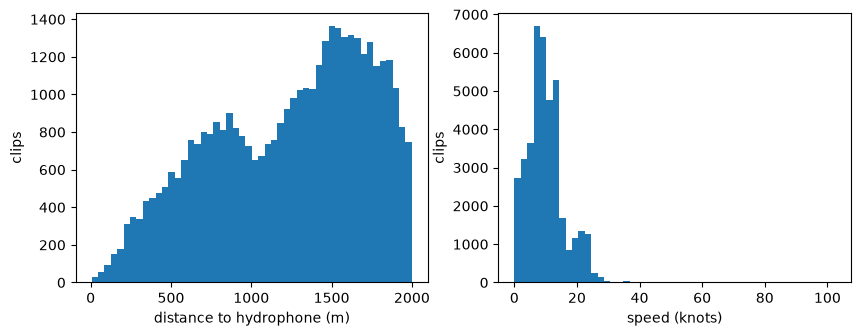

median distance 1322 m, median speed 9.3 knots


In [7]:
s = table[table.label != "background"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(s.mean_distance.dropna(), bins=50); ax[0].set_xlabel("distance to hydrophone (m)")
ax[1].hist(s.mean_sog.dropna(), bins=50); ax[1].set_xlabel("speed (knots)")
for a in ax: a.set_ylabel("clips")
plt.show()
print(f"median distance {s.mean_distance.median():.0f} m, median speed {s.mean_sog.median():.1f} knots")

Clips were only labelled as a ship when that ship was within 2 km, with no other ship within 4 km.
That's why distance stops at 2,000 m.

Does speed depend on the ship type? Of course it does: sailing boats and tugs are slower than passenger ferries.

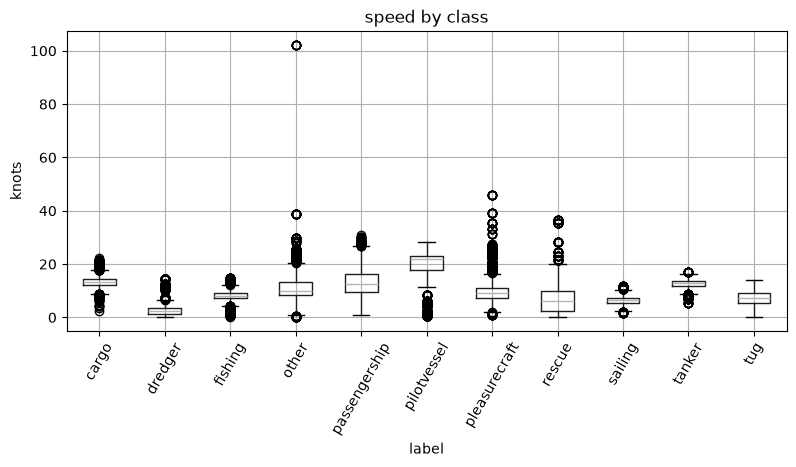

In [8]:
s.boxplot(column="mean_sog", by="label", rot=60, figsize=(9, 4))
plt.suptitle(""); plt.title("speed by class"); plt.ylabel("knots"); plt.show()

## 5. Listen

The audio lives in the 16.6 GB zip. If it was copied to this machine, you can play clips directly
from inside it (nothing gets unzipped).

In [9]:
from IPython.display import Audio, display

if AUDIO_ZIP.exists():
    from shipzip import SplitZip
    import features as F
    z = SplitZip(str(AUDIO_ZIP))
    for label in ("tanker", "sailing", "background"):
        r = table.index[table.label == label][0]
        wave, sr, _ = F.decode_wav(z.read(table.zip_name.iat[r]))
        print(f"{label}: {table.mean_distance.iat[r]:.0f} m away" if label != "background" else label)
        display(Audio(wave / np.abs(wave).max(), rate=sr))
else:
    print(f"audio zip not found at {AUDIO_ZIP}; skipping (copy gdrive_download/audio/ to listen).")

tanker: 599 m away


sailing: 1957 m away


background


## Try it

1. Which class has the most clips per ship? Why might that make it *easier* to overfit?
2. Find the hydrophone column's two values and count clips per hydrophone (`table.hydrophone.value_counts()`).
   Lesson 10 trains on one and tests on the other.
3. Plot `rms_db` (overall loudness of the clip) against `mean_distance` for ship clips.
   Is the link between loudness and distance as clear as you expected? Lesson 02 explains why not.